<a href="https://colab.research.google.com/github/adukirdat/deep_learning/blob/main/Implementation_of_Back_Propagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
wine = load_wine()

X = wine.data
y = wine.target

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("Features:", wine.feature_names)
print("Classes:", wine.target_names)

Input Shape: (178, 13)
Target Shape: (178,)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Classes: ['class_0' 'class_1' 'class_2']


In [3]:
def relu(x):
    return np.maximum(0, x)


def softmax(z):
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [4]:
sample = np.array([[2.0, 1.0, 0.1]])
print(softmax(sample))

[[0.65900114 0.24243297 0.09856589]]


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Data (First Sample):")
print(X[0])

print("\nScaled Data (First Sample):")
print(X_scaled[0])

Original Data (First Sample):
[1.423e+01 1.710e+00 2.430e+00 1.560e+01 1.270e+02 2.800e+00 3.060e+00
 2.800e-01 2.290e+00 5.640e+00 1.040e+00 3.920e+00 1.065e+03]

Scaled Data (First Sample):
[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
  1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
  1.01300893]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (142, 13)
X_test: (36, 13)
y_train: (142,)
y_test: (36,)


In [7]:
input_neurons = 13
hidden_neurons = 8
output_neurons = 3

print("Input Neurons:", input_neurons)
print("Hidden Neurons:", hidden_neurons)
print("Output Neurons:", output_neurons)

Input Neurons: 13
Hidden Neurons: 8
Output Neurons: 3


In [8]:
# Initialize weights
weights_input_hidden = np.random.randn(input_neurons, hidden_neurons)
weights_hidden_output = np.random.randn(hidden_neurons, output_neurons)

# Initialize biases
biases_hidden = np.zeros((1, hidden_neurons))
biases_output = np.zeros((1, output_neurons))

# Check shapes
print("W1 Shape:", weights_input_hidden.shape)
print("b1 Shape:", biases_hidden.shape)
print("W2 Shape:", weights_hidden_output.shape)
print("b2 Shape:", biases_output.shape)

W1 Shape: (13, 8)
b1 Shape: (1, 8)
W2 Shape: (8, 3)
b2 Shape: (1, 3)


In [9]:
def one_hot_encode(y, num_classes):
    one_hot = np.zeros((y.shape[0], num_classes))
    one_hot[np.arange(y.shape[0]), y] = 1
    return one_hot


y_train_encoded = one_hot_encode(y_train, output_neurons)
y_test_encoded = one_hot_encode(y_test, output_neurons)

print("Encoded Training Shape:", y_train_encoded.shape)
print("Encoded Testing Shape:", y_test_encoded.shape)

print("\nFirst 5 Encoded Labels:")
print(y_train_encoded[:5])

Encoded Training Shape: (142, 3)
Encoded Testing Shape: (36, 3)

First 5 Encoded Labels:
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [10]:
def categorical_cross_entropy(y_true, y_pred):
    epsilon = 1e-15

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        np.sum(y_true * np.log(y_pred), axis=1)
    )

    return loss

In [11]:
sample_true = np.array([[1, 0, 0]])
sample_pred = np.array([[0.7, 0.2, 0.1]])

print("Sample Loss:", categorical_cross_entropy(
    sample_true, sample_pred
))


Sample Loss: 0.35667494393873245


In [12]:
def forward_propagation(X, W1, b1, W2, b2):

    # Input to Hidden Layer
    z1 = np.dot(X, W1) + b1
    a1 = relu(z1)

    # Hidden to Output Layer
    z2 = np.dot(a1, W2) + b2
    a2 = softmax(z2)

    return z1, a1, z2, a2

In [13]:
def backward_propagation(X, y_true, z1, a1, z2, a2, W2):

    m = X.shape[0]

    # Output Layer Gradients
    dz2 = (a2 - y_true) / m
    dW2 = np.dot(a1.T, dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Hidden Layer Gradients
    da1 = np.dot(dz2, W2.T)
    dz1 = da1.copy()
    dz1[z1 <= 0] = 0

    dW1 = np.dot(X.T, dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [14]:
def update_parameters(W1, b1, W2, b2,
                      dW1, db1, dW2, db2, lr):

    W1 -= lr * dW1
    b1 -= lr * db1

    W2 -= lr * dW2
    b2 -= lr * db2

    return W1, b1, W2, b2

In [15]:
epochs = 100
learning_rate = 0.05

train_losses = []

for epoch in range(epochs):

    # 1. Forward Propagation
    z1, a1, z2, a2 = forward_propagation(
        X_train,
        weights_input_hidden,
        biases_hidden,
        weights_hidden_output,
        biases_output
    )

    # 2. Calculate Loss
    loss = categorical_cross_entropy(y_train_encoded, a2)
    train_losses.append(loss)

    # 3. Backpropagation
    dW1, db1, dW2, db2 = backward_propagation(
        X_train, y_train_encoded,
        z1, a1, z2, a2,
        weights_hidden_output
    )

    # 4. Update Parameters
    weights_input_hidden, biases_hidden, \
    weights_hidden_output, biases_output = update_parameters(
        weights_input_hidden, biases_hidden,
        weights_hidden_output, biases_output,
        dW1, db1, dW2, db2,
        learning_rate
    )

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss:.4f}")

Epoch 20/100, Loss: 0.7152
Epoch 40/100, Loss: 0.3714
Epoch 60/100, Loss: 0.2458
Epoch 80/100, Loss: 0.1832
Epoch 100/100, Loss: 0.1414


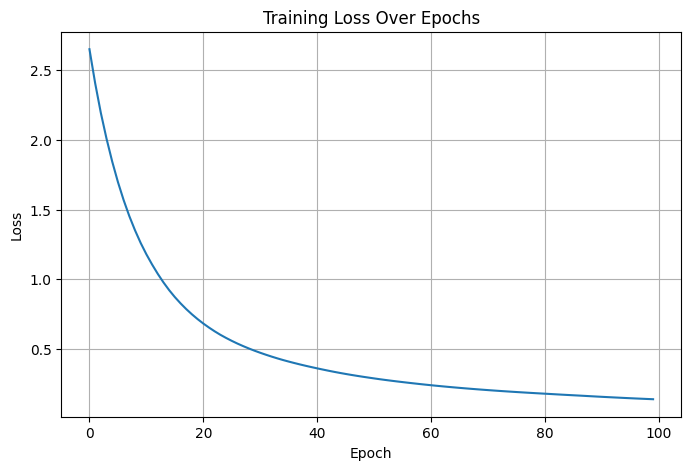

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses)

plt.title("Training Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.show()

In [19]:
def predict(X, W1, b1, W2, b2):

    _, _, _, probabilities = forward_propagation(
        X, W1, b1, W2, b2
    )

    predicted_classes = np.argmax(probabilities, axis=1)

    return predicted_classes

In [20]:
y_train_pred = predict(
    X_train,
    weights_input_hidden,
    biases_hidden,
    weights_hidden_output,
    biases_output
)

y_test_pred = predict(
    X_test,
    weights_input_hidden,
    biases_hidden,
    weights_hidden_output,
    biases_output
)

print("First 10 Actual Labels:", y_test[:10])
print("First 10 Predicted Labels:", y_test_pred[:10])

First 10 Actual Labels: [0 2 0 1 1 0 0 1 1 2]
First 10 Predicted Labels: [0 1 0 2 1 0 0 0 1 2]


In [21]:
train_accuracy = np.mean(y_train_pred == y_train)
test_accuracy = np.mean(y_test_pred == y_test)

print("Training Accuracy:", train_accuracy * 100, "%")
print("Testing Accuracy:", test_accuracy * 100, "%")

Training Accuracy: 96.47887323943662 %
Testing Accuracy: 88.88888888888889 %


In [22]:
# Training predictions (probabilities)
_, _, _, train_probabilities = forward_propagation(
    X_train,
    weights_input_hidden,
    biases_hidden,
    weights_hidden_output,
    biases_output
)

# Testing predictions (probabilities)
_, _, _, test_probabilities = forward_propagation(
    X_test,
    weights_input_hidden,
    biases_hidden,
    weights_hidden_output,
    biases_output
)

train_loss = categorical_cross_entropy(
    y_train_encoded, train_probabilities
)

test_loss = categorical_cross_entropy(
    y_test_encoded, test_probabilities
)

print("Final Training Loss:", train_loss)
print("Final Testing Loss:", test_loss)

Final Training Loss: 0.13966222041815146
Final Testing Loss: 0.28045913087961893
